# Fase 4 · Modelado con ML tradicional (Kaggle, Buena vs. Mala)

**Alcance de este cuaderno.** Línea base y tres modelos de ML tradicional (regresión logística, SVM RBF y
Random Forest) sobre el dataset de Kaggle, con hiperparámetros ajustados por `GridSearchCV` y validación cruzada
**agrupada por objeto**. Como la clase *Regular* todavía no existe (depende de las fotos propias y de *Mixed*), la tarea
aquí es **Buena vs. Mala** con las etiquetas débiles de Kaggle (Good → Buena, Bad → Mala).

**Reglas que se cumplen:**
* El **conjunto de test no se carga ni se usa**: aquí solo hay `train` y `val` (el test se usa una vez, al final).
* Estandarización **dentro** del `Pipeline` (estadísticos solo de train en cada pliegue).
* El entrenamiento se submuestrea a ≤ 1 100 imágenes por celda especie × clase; `val` conserva su distribución natural.
* Junto a cada modelo se reporta la línea base **"solo borde"** (misma familia y mismos hiperparámetros, viendo únicamente
  el borde de la imagen) para saber cuánto del rendimiento puede venir del fondo (ver el EDA, sección 7).

Técnicas **no vistas en clase** (se declaran en el informe): `StratifiedGroupKFold` y el histograma de color HSV.

In [1]:
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV

REPO = Path.cwd().parent if Path.cwd().name == "04_modelado" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
import features as ft
import models_classic as mc

PROC = REPO / "data" / "processed"
FIG = REPO / "04_modelado" / "figuras"
FIG.mkdir(exist_ok=True)
(PROC / "models").mkdir(parents=True, exist_ok=True)
SEED, CAP = 42, 1100
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["savefig.bbox"] = "tight"


def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.pdf")

## 1. Datos: solo train y val

In [2]:
part = pd.read_pickle(PROC / "partition.pkl")           # generada en el EDA (semilla 42)
dev = part[part["split"].isin(["train", "val"])].copy()  # el test NO se usa en este cuaderno
train_full, val = dev[dev["split"] == "train"], dev[dev["split"] == "val"]
train = mc.cap_per_cell(train_full, ["species", "label_weak"], CAP, SEED)
conteo = pd.concat({"train completo": train_full.groupby(["species", "label_weak"]).size(),
                    f"train (tope {CAP})": train.groupby(["species", "label_weak"]).size(),
                    "val": val.groupby(["species", "label_weak"]).size()}, axis=1)
print(f"train: {len(train_full):,} -> {len(train):,} imágenes | val: {len(val):,} | grupos en train: {train['group'].nunique():,}")
assert not set(train["group"]) & set(val["group"]), "fuga entre train y val"
conteo

train: 13,176 -> 10,032 imágenes | val: 2,632 | grupos en train: 2,205


train completo  train (tope 1100)  val
species     label_weak                                        
apple       Buena                  821                821  164
            Mala                   815                815  163
banana      Buena                  795                795  159
            Mala                   776                776  156
guava       Buena                  823                823  165
            Mala                   807                807  161
lime        Buena                  781                781  157
            Mala                   775                775  155
orange      Buena                  869                869  174
            Mala                   822                822  160
pomegranate Buena                 4244               1100  848
            Mala                   848                848  170

## 2. Características de color (histograma HSV 8×4×4 + 8 estadísticos)

In [3]:
thumbs = np.load(PROC / "thumbs64.npy", mmap_mode="r")


def featurize(rows, region):
    """136 características: histograma HSV (128) + estadísticos de color (8) de una región."""
    t = np.asarray(thumbs[rows])
    return np.hstack([ft.hsv_histogram(t, region=region), ft.color_stats(t, region=region)])


X = {reg: {"train": featurize(train["row"].to_numpy(), reg), "val": featurize(val["row"].to_numpy(), reg)}
     for reg in ("full", "border")}
ytr, yva = train["label_weak"].to_numpy(), val["label_weak"].to_numpy()
gtr, sva = train["group"].to_numpy(), val["species"].to_numpy()
print({reg: v["train"].shape for reg, v in X.items()})

{'full': (10032, 136), 'border': (10032, 136)}


## 3. Ajuste con `GridSearchCV` agrupado (imagen completa)

Validación cruzada de 5 pliegues **estratificada y agrupada por objeto** (ningún grupo aparece en dos pliegues),
puntuación F1 macro. Se reporta también la brecha de sobreajuste (F1 en train − F1 en val).

In [4]:
zoo = mc.model_zoo(SEED)
resultados, mejores, grids = [], {}, {}
for nombre, (est, malla) in zoo.items():
    t0 = time.time()
    if malla:
        gs = GridSearchCV(est, malla, scoring="f1_macro", cv=mc.make_cv(5, SEED), n_jobs=-1, refit=True)
        gs.fit(X["full"]["train"], ytr, groups=gtr)
        modelo, grids[nombre] = gs.best_estimator_, gs
        cv_media, cv_std, params = gs.best_score_, gs.cv_results_["std_test_score"][gs.best_index_], gs.best_params_
    else:
        modelo = est.fit(X["full"]["train"], ytr)
        cv_media, cv_std, params = np.nan, np.nan, {}
    fit_s = time.time() - t0
    t1 = time.time()
    pred_va = modelo.predict(X["full"]["val"])
    ms_img = (time.time() - t1) / len(yva) * 1000
    ev_va = mc.evaluate(yva, pred_va, sva)
    ev_tr = mc.evaluate(ytr, modelo.predict(X["full"]["train"]))
    mejores[nombre] = modelo
    joblib.dump(modelo, PROC / "models" / f"{nombre}_full.joblib")
    resultados.append({"modelo": nombre, "mejores_hiperparametros": params, "F1_cv": cv_media, "DE_cv": cv_std,
                       "F1_train": ev_tr["global"]["F1_macro"], "F1_val": ev_va["global"]["F1_macro"],
                       "brecha_train_val": ev_tr["global"]["F1_macro"] - ev_va["global"]["F1_macro"],
                       "exactitud_val": ev_va["global"]["exactitud"], "EE_val": ev_va["global"]["EE"],
                       "kappa_val": ev_va["global"]["kappa_w"], "ajuste_s": fit_s, "ms_por_imagen": ms_img})
res = pd.DataFrame(resultados)
res.round(3)

,modelo,mejores_hiperparametros,F1_cv,DE_cv,F1_train,F1_val,brecha_train_val,exactitud_val,EE_val,kappa_val,ajuste_s,ms_por_imagen
0,baseline_mayoritaria,{},NaN,NaN,0.341,0.388,-0.047,0.633,0.009,0.000,0.016,0.000
1,logreg,{'clf__C': 0.1},0.893,0.027,0.923,0.891,0.032,0.897,0.006,0.783,7.784,0.000
2,svm_rbf,"{'clf__C': 10.0, 'clf__gamma': 0.01}",0.941,0.026,0.998,0.944,0.054,0.948,0.004,0.889,51.514,0.130
3,random_forest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.950,0.033,1.000,0.947,0.053,0.950,0.004,0.893,47.242,0.012


In [5]:
# Transparencia del ajuste: las 3 mejores combinaciones de cada malla
for nombre, gs in grids.items():
    top = (pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
           .sort_values("rank_test_score").head(3))
    print(f"--- {nombre}: {len(gs.cv_results_['params'])} combinaciones x 5 pliegues")
    print(top.round(3).to_string(index=False))

--- logreg: 4 combinaciones x 5 pliegues
          params  mean_test_score  std_test_score  rank_test_score
 {'clf__C': 0.1}            0.893           0.027                1
{'clf__C': 0.01}            0.891           0.031                2
 {'clf__C': 1.0}            0.890           0.031                3
--- svm_rbf: 9 combinaciones x 5 pliegues
                                params  mean_test_score  std_test_score  rank_test_score
  {'clf__C': 10.0, 'clf__gamma': 0.01}            0.941           0.026                1
{'clf__C': 100.0, 'clf__gamma': 0.003}            0.940           0.025                2
 {'clf__C': 100.0, 'clf__gamma': 0.01}            0.939           0.023                3
--- random_forest: 8 combinaciones x 5 pliegues
                                                         params  mean_test_score  std_test_score  rank_test_score
{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}            0.950           0.033                1
  {'max_depth': 2

## 4. Línea base "solo borde" (mismos hiperparámetros, viendo solo el fondo)

In [6]:
from sklearn.base import clone
borde = []
for nombre, modelo in mejores.items():
    m = clone(modelo).fit(X["border"]["train"], ytr)
    pred = m.predict(X["border"]["val"])
    ev = mc.evaluate(yva, pred, sva)
    joblib.dump(m, PROC / "models" / f"{nombre}_border.joblib")
    borde.append({"modelo": nombre, "F1_val_borde": ev["global"]["F1_macro"], "exactitud_val_borde": ev["global"]["exactitud"],
                  "EE_val_borde": ev["global"]["EE"]})
comp = res[["modelo", "F1_val"]].merge(pd.DataFrame(borde), on="modelo")
comp["F1_val_imagen_completa"] = comp.pop("F1_val")
comp["ventaja_sobre_borde"] = comp["F1_val_imagen_completa"] - comp["F1_val_borde"]
comp.round(3)

,modelo,F1_val_borde,exactitud_val_borde,EE_val_borde,F1_val_imagen_completa,ventaja_sobre_borde
0,baseline_mayoritaria,0.388,0.633,0.009,0.388,0.000
1,logreg,0.852,0.860,0.007,0.891,0.040
2,svm_rbf,0.903,0.910,0.006,0.944,0.041
3,random_forest,0.931,0.936,0.005,0.947,0.015


## 5. Métricas por especie (conjunto de validación)

In [7]:
por_esp = {}
for nombre in ("logreg", "svm_rbf", "random_forest"):
    por_esp[nombre] = mc.evaluate(yva, mejores[nombre].predict(X["full"]["val"]), sva)["per_species"]["F1_macro"]
por_esp["borde: " + res.loc[res["F1_val"].idxmax(), "modelo"]] = mc.evaluate(
    yva, joblib.load(PROC / "models" / f"{res.loc[res['F1_val'].idxmax(), 'modelo']}_border.joblib").predict(X["border"]["val"]), sva
)["per_species"]["F1_macro"]
tabla_esp = pd.DataFrame(por_esp)
tabla_esp["n_val"] = val.groupby("species").size()
tabla_esp.round(3)

,logreg,svm_rbf,random_forest,borde: random_forest,n_val
apple,0.708,0.855,0.820,0.856,327
banana,0.914,0.987,0.997,0.997,315
guava,0.871,0.945,0.895,0.908,326
lime,0.933,0.949,0.997,0.923,312
orange,0.820,0.865,0.907,0.889,334
pomegranate,0.956,0.990,0.991,0.950,1018


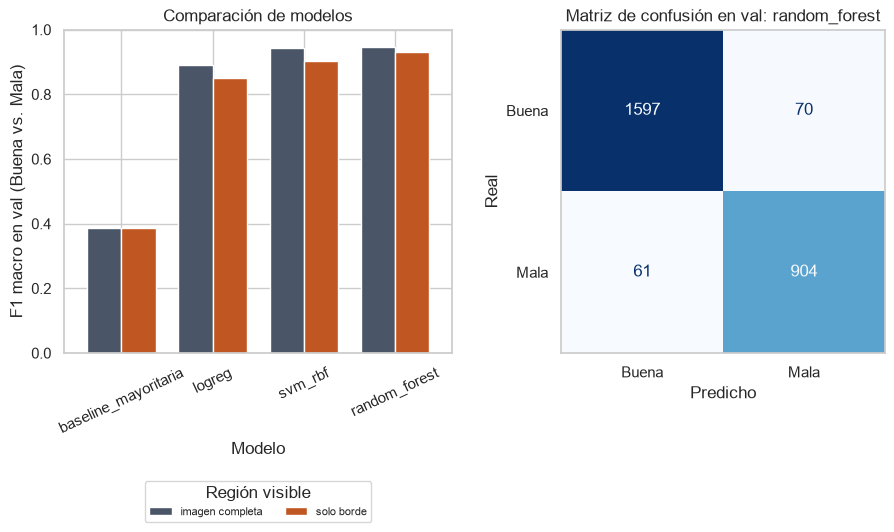

In [8]:
mejor = res.loc[res["F1_val"].idxmax(), "modelo"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
orden = ["baseline_mayoritaria", "logreg", "svm_rbf", "random_forest"]
plot = pd.DataFrame({"imagen completa": res.set_index("modelo")["F1_val"],
                     "solo borde": comp.set_index("modelo")["F1_val_borde"]}).reindex(orden)
plot.plot.bar(ax=axes[0], color={"imagen completa": "#4A5568", "solo borde": "#C05621"}, width=0.75)
axes[0].set_ylim(0, 1); axes[0].set_ylabel("F1 macro en val (Buena vs. Mala)"); axes[0].set_xlabel("Modelo")
axes[0].set_title("Comparación de modelos"); axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(title="Región visible", loc="upper center", bbox_to_anchor=(0.5, -0.38), ncol=2, fontsize=8)
ConfusionMatrixDisplay.from_predictions(yva, mejores[mejor].predict(X["full"]["val"]), ax=axes[1], cmap="Blues", colorbar=False)
axes[1].grid(False); axes[1].set_title(f"Matriz de confusión en val: {mejor}"); axes[1].set_xlabel("Predicho"); axes[1].set_ylabel("Real")
guardar(fig, "modelos_clasicos")
plt.show()

In [9]:
# Tabla de resultados para el informe (se versiona: es pequeña)
final = res.drop(columns=["mejores_hiperparametros"]).assign(mejores_hiperparametros=res["mejores_hiperparametros"].astype(str))
final = final.merge(comp[["modelo", "F1_val_borde"]], on="modelo")
final.to_csv(REPO / "04_modelado" / "resultados_modelos_clasicos.csv", index=False)
print("Mejor en val por F1 macro:", mejor)

Mejor en val por F1 macro: random_forest


In [10]:
# Modelo provisional para la app (Buena vs. Mala). Se reemplaza al entrenar con la clase Regular.
# Se usa el Random Forest porque empata con la SVM dentro de 1 EE y entrega probabilidades (predict_proba).
destino = REPO / "06_despliegue" / "modelo"
destino.mkdir(parents=True, exist_ok=True)
joblib.dump(mejores["random_forest"], destino / "calidad.joblib", compress=3)
print(f"Modelo de la app: {(destino / 'calidad.joblib').stat().st_size / 1e6:.1f} MB | clases: {list(mejores['random_forest'].classes_)}")

Modelo de la app: 2.9 MB | clases: ['Buena', 'Mala']


## 6. Lectura de los resultados (validación, Buena vs. Mala)

1. **Los tres modelos superan con holgura la línea base.** La mayoritaria da F1 macro de 0.388 (exactitud 0.633); la
   regresión logística 0.891, la SVM 0.944 y el Random Forest 0.947. **SVM y Random Forest no se distinguen**: la
   diferencia (0.003) es menor que un error estándar de la exactitud (0.004).
2. **Sobreajuste moderado.** En train el F1 es 0.998 (SVM) y 1.000 (Random Forest) frente a 0.944 y 0.947 en val (brecha
   de ~0.05); la regresión logística, de menor capacidad, tiene brecha de 0.032. La validación cruzada agrupada (0.941 y
   0.950) coincide con val, así que la selección de hiperparámetros no está sesgada respecto de val.
3. **Buena parte del rendimiento puede venir del fondo.** Con **solo el borde** de la imagen y los mismos hiperparámetros se
   obtiene 0.852 (logística), 0.903 (SVM) y 0.931 (Random Forest); ver la imagen completa solo añade 0.040, 0.041 y 0.015 de
   F1. En banana, el Random Forest alcanza 0.997 con la imagen completa **y** con solo el borde. Por eso estas métricas
   **no demuestran que el modelo haya aprendido la calidad de la fruta**: son una cota superior del rendimiento en este
   dataset y **no se extrapolan a fotos propias**, donde el fondo está controlado.
4. **Por especie** (Random Forest): de 0.820 en manzana a 0.997 en banana y en lima; la manzana es la más difícil
   también para la regresión logística (0.708) y la SVM (0.855).
5. **Costo de cómputo** (dimensión ambiental): las columnas `ajuste_s` (ajuste con `GridSearchCV`, `n_jobs=-1` en una CPU
   de 10 núcleos) y `ms_por_imagen` (inferencia sin contar la extracción de características) de la tabla de la sección 3
   son tiempos de **una sola corrida** y varían con la carga de la máquina; el ajuste de la SVM y del Random Forest es del
   orden de un minuto, y el de la regresión logística, bastante menor. La energía queda por medir **[MEDIR]**.
6. **Límites que se declaran:** la tarea es binaria porque *Regular* aún no existe; las etiquetas de Kaggle son débiles; puede
   haber fuga residual por casi-duplicados; y **el test no se ha usado**: el modelo final se elegirá tras evaluar en fotos
   propias y en frutas de *Mixed*, y solo entonces se usa el test, una vez.